# Telco Customer Churn Prediction

## CM2604 - Machine Learning - Individual Coursework

---

**Name** : Nadija Ranawaka  
**IIT** : 20240696
**RGU** : 2522857

## 1. Introduction

Customer churn refers to a situation where a customer stops using a company's products or services. Predicting customer churn is an important task for telecommunications companies because identifying customers who are likely to leave can help the company take appropriate actions to improve customer retention.

In this project, machine learning classification techniques are used to predict whether a telecommunications customer will churn. The Telco Customer Churn dataset contains information about customers' demographic characteristics, services, contract information, tenure, and billing details.

The project consists of three main tasks. First, Exploratory Data Analysis (EDA) is performed to understand the characteristics and patterns within the dataset. Second, the data is preprocessed and three binary classification algorithms, K-Nearest Neighbours (KNN), Logistic Regression, and Random Forest, are implemented and optimized using hyperparameter tuning. Finally, the models are evaluated and compared using appropriate classification metrics.

The project also considers ethical issues associated with developing and deploying machine learning models for customer churn prediction.

## 2. Dataset Description

The dataset used in this project is the Telco Customer Churn dataset. It contains information about 7,043 telecommunications customers and 21 attributes. The attributes describe different aspects of the customers, including demographic information, subscribed services, account information, contract type, customer tenure, and charges.

The target variable is `Churn`, which indicates whether a customer has discontinued the telecommunications service.

The target variable contains two possible classes:

- `Yes` — the customer has churned.
- `No` — the customer has not churned.

Since the target variable contains two classes, this project is a **binary classification problem**.

## 3. Importing Libraries

The required Python libraries are imported for data manipulation, numerical operations, data visualization, and statistical analysis.

In [6]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

## 4. Loading the Dataset

The Telco Customer Churn dataset is loaded into a Pandas DataFrame. A DataFrame provides a tabular structure that allows the dataset to be efficiently inspected, cleaned, visualized, and analyzed.

In [7]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

## 5. Initial Dataset Inspection

An initial inspection of the dataset is performed to verify that the data has been loaded correctly and to understand its basic structure. The first few records are displayed to observe the types of information contained in the dataset.

In [8]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 5.1 Dataset Dimensions

The dimensions of the dataset are examined to determine the number of customer records and attributes available for analysis.

In [10]:
df.shape

(7043, 21)

The dataset contains 7,043 customer records and 21 attributes. Each row represents an individual telecommunications customer, while each column represents a customer attribute such as demographic information, subscribed services, contract details, tenure, and billing information. The `Churn` attribute will be used as the target variable for the binary classification task.

### 5.2 Dataset Information

The `info()` method is used to examine the data types and number of non-null observations for each variable. This provides an initial understanding of the numerical and categorical variables and helps identify potential missing values.

In [19]:
dataset_info = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notnull().sum().values,
    "Missing Values": df.isnull().sum().values
})

dataset_info.style.hide(axis="index")

Column,Data Type,Non-Null Count,Missing Values
customerID,str,7043,0
gender,str,7043,0
SeniorCitizen,int64,7043,0
Partner,str,7043,0
Dependents,str,7043,0
tenure,int64,7043,0
PhoneService,str,7043,0
MultipleLines,str,7043,0
InternetService,str,7043,0
OnlineSecurity,str,7043,0


### 5.3 Statistical Summary

Descriptive statistics are examined for the numerical variables in the dataset. This provides information such as the mean, standard deviation, minimum, maximum, and quartile values. These statistics help identify the general distribution and range of the numerical attributes.

In [20]:
statistical_summary = df.describe().T

statistical_summary = statistical_summary[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
]

statistical_summary

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


The statistical summary provides an overview of the numerical attributes in the dataset. It shows the number of available observations (`count`), average value (`mean`), variation in the data (`std`), minimum and maximum values, and the 25th, 50th, and 75th percentiles. This gives an initial understanding of the range and distribution of the numerical attributes before performing more detailed exploratory data analysis.

### 5.4 Dataset Attributes

The names of all variables are examined to understand the attributes available in the dataset and to identify the target variable used for classification.

In [22]:
attribute_description = pd.DataFrame({
    "Attribute": [
        "customerID",
        "gender",
        "SeniorCitizen",
        "Partner",
        "Dependents",
        "tenure",
        "PhoneService",
        "MultipleLines",
        "InternetService",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies",
        "Contract",
        "PaperlessBilling",
        "PaymentMethod",
        "MonthlyCharges",
        "TotalCharges",
        "Churn"
    ],
    "Description": [
        "Unique identifier assigned to each customer.",
        "Customer's gender.",
        "Indicates whether the customer is a senior citizen.",
        "Indicates whether the customer has a partner.",
        "Indicates whether the customer has dependents.",
        "Number of months the customer has been with the company.",
        "Indicates whether the customer has a phone service.",
        "Indicates whether the customer has multiple phone lines.",
        "Type of internet service used by the customer.",
        "Indicates whether the customer has online security.",
        "Indicates whether the customer has online backup.",
        "Indicates whether the customer has device protection.",
        "Indicates whether the customer has technical support.",
        "Indicates whether the customer has a streaming TV service.",
        "Indicates whether the customer has a streaming movie service.",
        "Type of contract held by the customer.",
        "Indicates whether the customer uses paperless billing.",
        "Payment method used by the customer.",
        "Monthly amount charged to the customer.",
        "Total amount charged to the customer.",
        "Indicates whether the customer has left the company."
    ]
})

attribute_description.style.hide(axis="index")

Attribute,Description
customerID,Unique identifier assigned to each customer.
gender,Customer's gender.
SeniorCitizen,Indicates whether the customer is a senior citizen.
Partner,Indicates whether the customer has a partner.
Dependents,Indicates whether the customer has dependents.
tenure,Number of months the customer has been with the company.
PhoneService,Indicates whether the customer has a phone service.
MultipleLines,Indicates whether the customer has multiple phone lines.
InternetService,Type of internet service used by the customer.
OnlineSecurity,Indicates whether the customer has online security.


### 5.5 Missing Values

Missing values can affect the performance and reliability of machine learning models. Therefore, the number of missing values in each attribute is examined before proceeding with further analysis.

In [23]:
missing_values = pd.DataFrame({
    "Attribute": df.columns,
    "Missing Values": df.isnull().sum().values
})

missing_values.style.hide(axis="index")

Attribute,Missing Values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


The dataset does not contain any explicit missing (`NaN`) values. However, the `TotalCharges` attribute contains blank string values that are not detected as standard missing values. These will be handled during the data preprocessing stage.

### 5.6 Duplicate Records

Duplicate records can introduce bias into the analysis and may cause certain observations to be given more importance than intended. Therefore, the dataset is checked for duplicate rows.

In [24]:
duplicate_count = df.duplicated().sum()

duplicate_summary = pd.DataFrame({
    "Measure": ["Duplicate Records"],
    "Count": [duplicate_count]
})

duplicate_summary.style.hide(axis="index")

Measure,Count
Duplicate Records,0


The dataset contains no duplicate records. Therefore, no duplicate customer records need to be removed at this stage."

## 6. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to identify patterns, distributions, relationships, and potential issues within the dataset. Understanding these characteristics is important before developing the classification models.

### 6.1 Churn Distribution

The distribution of the target variable, `Churn`, is examined to determine the proportion of customers who churned and those who remained with the service. This is important for understanding the class distribution of the classification problem.

In [25]:
churn_counts = df["Churn"].value_counts()

churn_counts

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [26]:
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

churn_percentages

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

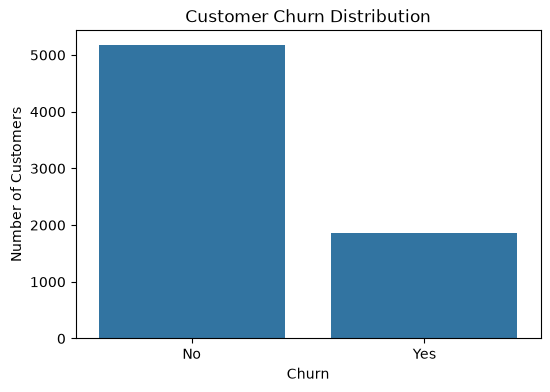

In [27]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

The target variable is imbalanced, with 73.46% of customers not churning and 26.54% churning. This indicates that the dataset contains substantially more customers who remained with the company than customers who left. Therefore, accuracy alone may not be sufficient for evaluating the classification models, and metrics such as precision, recall, and F1-score should also be considered.

### 6.2 Tenure Distribution by Churn

The relationship between customer tenure and churn is examined to determine whether customers who leave the company tend to have shorter or longer periods of service. This may help identify whether customer loyalty or length of time with the company is associated with churn.

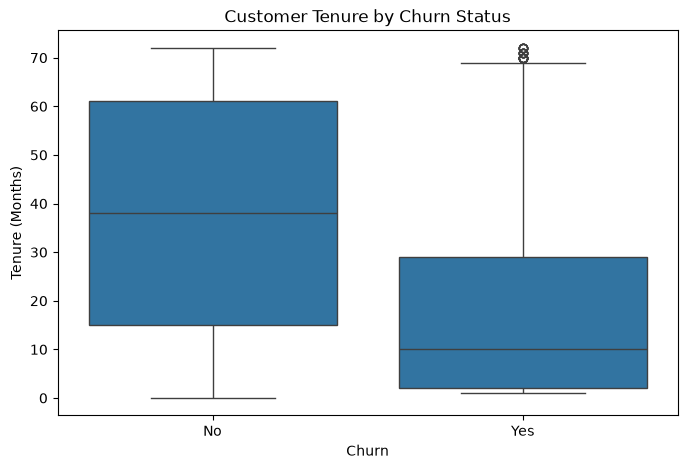

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

The boxplot shows a clear difference in customer tenure between the two churn groups. Customers who did not churn generally have longer tenures, while customers who churned tend to have shorter tenures. This suggests that customers who have been with the company for a shorter period may be more likely to churn. A small number of high-tenure customers are also observed as outliers within the churned group.

### 6.3 Monthly Charges by Churn

The relationship between monthly charges and customer churn is examined to determine whether customers who leave the company tend to have higher or lower monthly charges compared with customers who remain.

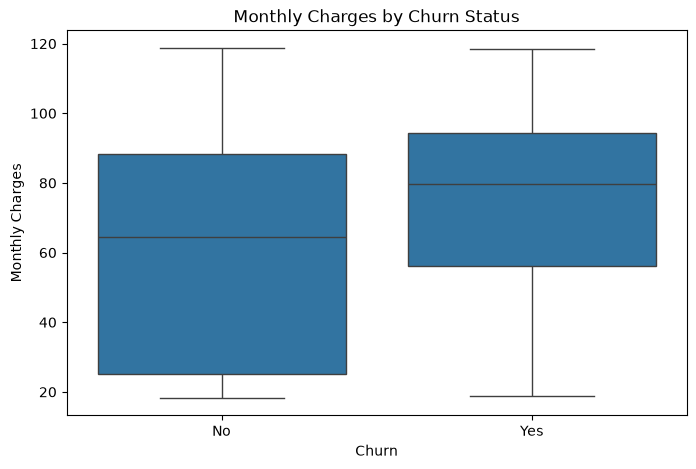

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

The boxplot shows that customers who churned generally have higher monthly charges than customers who remained with the company. The central range for churned customers is concentrated at higher charge values, suggesting that customers with higher monthly charges may be more likely to churn. However, this relationship represents an observed association and does not imply that higher charges directly cause customers to leave.

### 6.4 Contract Type and Churn

The relationship between contract type and customer churn is examined to determine whether customers with different contract durations have different levels of churn. Churn rates are compared across month-to-month, one-year, and two-year contracts.

In [30]:
contract_churn_rate = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn_rate

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


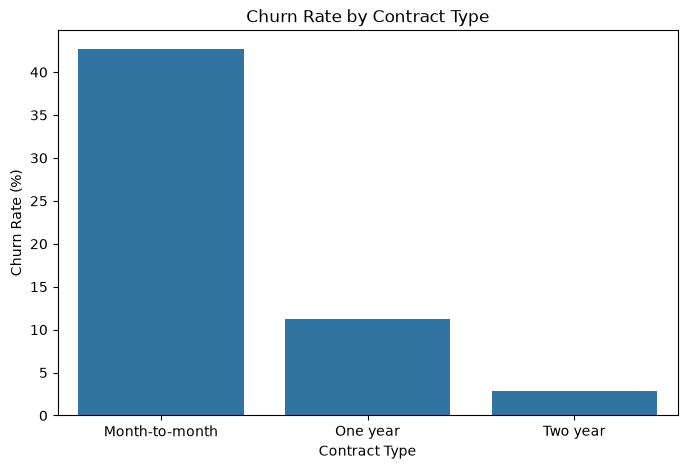

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn_rate.index,
    y=contract_churn_rate["Yes"]
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

The analysis shows a strong relationship between contract type and customer churn. Customers with month-to-month contracts have the highest churn rate at 42.71%, compared with 11.27% for one-year contracts and only 2.83% for two-year contracts. This suggests that customers on shorter-term contracts are more likely to churn than customers on longer-term contracts. However, this observed relationship does not establish that contract type directly causes customers to churn.

### 6.5 Internet Service and Churn

The relationship between internet service type and customer churn is examined to determine whether customers using different types of internet services have different churn rates.

In [32]:
internet_churn_rate = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn_rate

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


The analysis shows a clear difference in churn rates across internet service types. Customers using fiber optic internet have the highest churn rate at 41.89%, compared with 18.96% for DSL customers and 7.40% for customers without internet service. This suggests that internet service type may be associated with customer churn. However, this relationship does not establish that the type of internet service directly causes customers to churn.

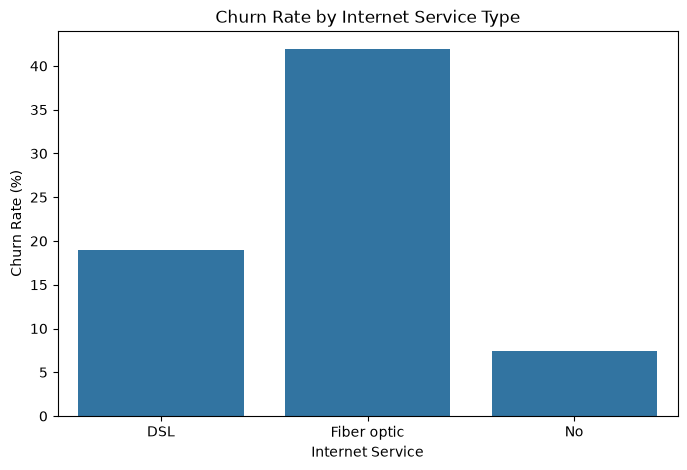

In [33]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=internet_churn_rate.index,
    y=internet_churn_rate["Yes"]
)

plt.title("Churn Rate by Internet Service Type")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.show()

### 6.6 Payment Method and Churn

The relationship between payment method and customer churn is examined to determine whether customers using different payment methods have different churn rates.

In [34]:
payment_churn_rate = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn_rate

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


The analysis shows a noticeable difference in churn rates across payment methods. Customers who use electronic checks have the highest churn rate at 45.29%, while customers using automatic credit card payments have the lowest churn rate at 15.24%. The churn rates for automatic bank transfers and mailed checks are 16.71% and 19.11%, respectively. This suggests that payment method may be associated with customer churn, although the observed relationship does not establish that payment method directly causes customers to churn.

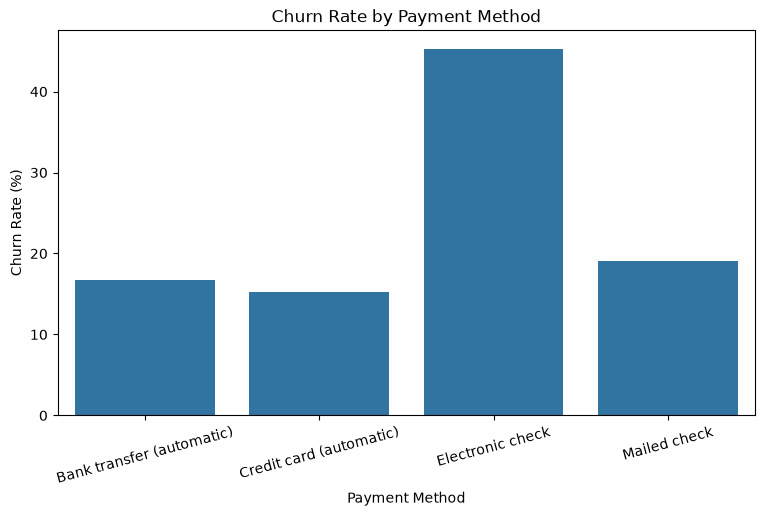

In [35]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=payment_churn_rate.index,
    y=payment_churn_rate["Yes"]
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)

plt.show()